In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# We create a shared transmission rate
transmission_rate = 1  # 1 Hz
oversampling_factor = 3
bit_change = 1

In [3]:
# First we generate the manchester data, where data is a byte that converts to an array of bits
def manchester_encode(data):
    # Convert the byte to a binary string
    binary_string = format(data, '08b')
    
    # Create the Manchester encoded signal
    manchester_signal = []
    for bit in binary_string:
        if bit == '0':
            manchester_signal.append(1)  # High to low transition
            manchester_signal.append(0)
        else:
            manchester_signal.append(0)
            manchester_signal.append(1)
    return manchester_signal

In [4]:
# Flatten the list of bits to a single list
def flatten(lst):
    return [item for sublist in lst for item in sublist]

bytes = flatten(list(map(manchester_encode, [0x7e]*1000)))
print(bytes)

[1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 

In [5]:
# Now we create the oversampled signal
# However, randomly the signal may be delayed and add an additional bit in the bitstream
# We call this STO for signal time offset and it works by either being to slow and therefore adding 4 1/0s or being too fast and adding 2 1/0s
# This function should randomly add a delay to the signal
def oversample(signal, oversampling_factor, probs=[0.005, 0.005, 0.99]):
    had_change = 0
    res = []
    for bit in signal:
        sto = np.random.choice([-1, 0, 1], p=probs)
        # If sto is -1, we add oversampling factor + 1 if the bit
        if sto == -1:
            had_change = -bit_change 
            res = res + ([bit] * (oversampling_factor + bit_change))
        # If sto is 0, we add 2 if the bit
        elif sto == 0:
            had_change = bit_change
            res = res + ([bit] * (oversampling_factor - bit_change))
        # If sto is 1, we add 1 if the bit
        else:
            res = res + ([bit] * (oversampling_factor))

    return res[0:len(signal) * oversampling_factor]


In [6]:
oversampled_signal = oversample(bytes, oversampling_factor)
print(oversampled_signal)


[1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 

Now we assume that the emitter will emit 2 x the transmission rate as it takes two cycles in order to emit one bit

Therefore, 2 x oversampling factor is equal to the transmission rate in time

In [7]:
# Now we assume that the receiver will sample the signal at the correct rate
# We will try to convert the oversampled signal back to the original bit
# We use majority voting to determine the value of the bit
def sample_signal(signal, oversampling_factor):
    # We will sample the signal at the oversampling rate
    print(len(signal))
    sampled_signal = []
    for i in range(0, len(signal), oversampling_factor):
        # We take the majority of the bits in the oversampled signal
        bit = signal[i:i + oversampling_factor]
        sampled_signal.append(1 if sum(bit) > len(bit) / 2 else 0)
    return sampled_signal

sampled_signal = sample_signal(oversampled_signal, oversampling_factor)
print(sampled_signal)

47997
[1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 

In [ ]:

def process_stable_bits(current_bit):
    IDEAL_THRESHOLD = oversampling_factor  # Assuming a threshold value for the example
    saved_bit = 0xFF  # Initialize to an invalid state
    last_bit = 0xFF

    stable_count = 0
    threshold_diff = 0

    # Here we have got either 1111 or 0000
    # Meaning the next bits can be (threshold - 1)
    if saved_bit == current_bit and threshold_diff == 0:
        threshold_diff = 1
        return -1

    if current_bit == last_bit:
        stable_count += 1
    else:
        last_bit = current_bit
        stable_count = 1

    if stable_count == (IDEAL_THRESHOLD - threshold_diff):
        threshold_diff = 0  # Reset threshold_diff
        tmp = last_bit
        saved_bit = last_bit  # Save the stable bit
        stable_count = 0  # Reset the stable count after processing
        last_bit = 0xFF  # Reset last_bit to av
        return tmp

    return -1  # Indicate that the bit is not stable yet

In [9]:
# Now we decode the signal back to the original byte
def manchester_decode(signal):
    # We will decode the Manchester signal back to the original byte
    decoded_byte = 0
    for i in range(0, len(signal), 2):
        # Make sure that we are not out of bounds
        if i + 1 >= len(signal):
            break
        if signal[i] == 1 and signal[i + 1] == 0:
            decoded_byte = (decoded_byte << 1) | 0
        elif signal[i] == 0 and signal[i + 1] == 1:
            decoded_byte = (decoded_byte << 1) | 1
    return decoded_byte
# Split sampled signal into chucks of 16 bits
sampled_signal_chunks = [sampled_signal[i:i + 16] for i in range(0, len(sampled_signal), 16)]

decoded_byte = list(map(manchester_decode, sampled_signal_chunks))
print(decoded_byte)

[126, 126, 62, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 79, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 8, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 95, 63, 63, 63, 63, 63, 16, 32, 32, 32, 32, 32, 32, 32, 35, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 16, 159, 159, 128, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 23, 63, 63, 63, 63, 63, 24, 32, 32, 32, 32, 32, 32, 35, 63, 24, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 33, 63, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 32, 39, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 30, 32, 32, 32, 32, 32, 32, 32,

In [10]:
# Lastly, we calculate the error rate between the original byte and the decoded byte
def calculate_error_rate(original, decoded):
    # We will calculate the error rate by comparing the original byte and the decoded byte
    original_bits = format(original, '08b')
    decoded_bits = format(decoded, '08b')
    errors = sum(1 for o, d in zip(original_bits, decoded_bits) if o != d)
    return errors / len(original_bits)


In [11]:
# Now run a lot of simulations to see the error rate
def run_simulations(num_simulations, oversampling_factor):
    bytes = flatten(list(map(manchester_encode, [0x7e] * num_simulations))) #np.random.randint(0, 256)
    oversampled_signal = oversample(bytes, oversampling_factor)
    sampled_signal = sample_signal(oversampled_signal, oversampling_factor)
    sampled_signal_chunks = [sampled_signal[i:i + 16] for i in range(0, len(sampled_signal), 16)]
    bit_error_rates = []
    for sample in sampled_signal_chunks:
        decoded_byte = manchester_decode(sample)
        error_rate = calculate_error_rate(0x7e, decoded_byte)
        print(f"Original: {0x7e}, Decoded: {decoded_byte}, Error Rate: {error_rate:.2%}")
        bit_error_rates.append(error_rate)
    return np.mean(bit_error_rates), np.std(bit_error_rates)


num_simulations = 1000
mean, std = run_simulations(num_simulations, oversampling_factor)
print(f"Mean Error Rate: {mean:.2%}, Std Error Rate: {std:.2%}")


48000
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Origina

48000
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Original: 126, Decoded: 126, Error Rate: 0.00%
Origina

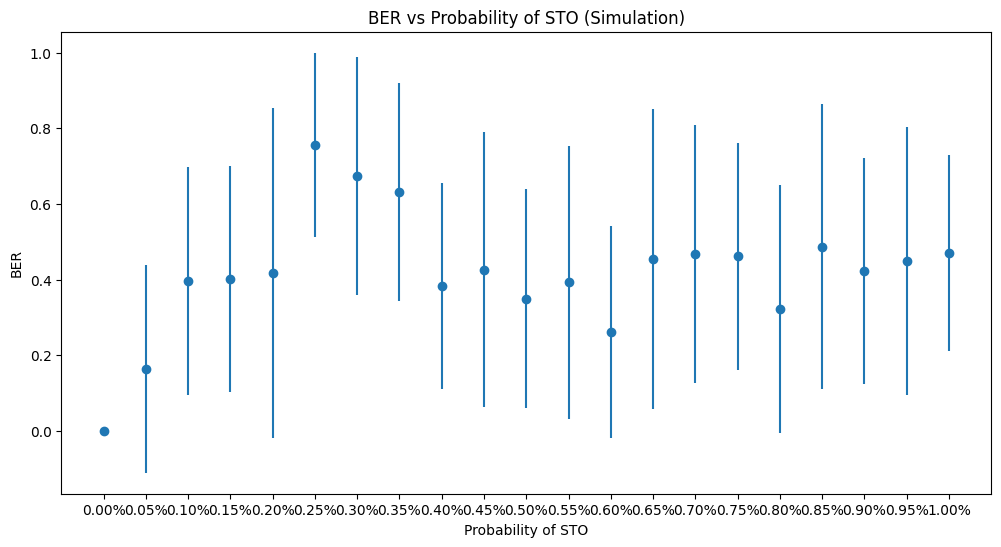

In [12]:
# now make the same simulation with varying probabilities for the STO
# Collect the data in two different lists and make a scatter plot
def run_simulations_varying_probs(num_simulations, oversampling_factor, probs):
    bytes = flatten(list(map(manchester_encode, [0x7e] * num_simulations))) #np.random.randint(0, 256)
    oversampled_signal = oversample(bytes, oversampling_factor, probs)
    sampled_signal = sample_signal(oversampled_signal, oversampling_factor)
    sampled_signal_chunks = [sampled_signal[i:i + 16] for i in range(0, len(sampled_signal), 16)]
    bit_error_rates = []
    for sample in sampled_signal_chunks:
        decoded_byte = manchester_decode(sample)
        error_rate = calculate_error_rate(0x7e, decoded_byte)
        print(f"Original: {0x7e}, Decoded: {decoded_byte}, Error Rate: {error_rate:.2%}")
        bit_error_rates.append(error_rate)
    return np.mean(bit_error_rates), np.std(bit_error_rates)

# Now we run the simulation with varying probabilities
# Generate a list of probabilities for the STO where the two first items are the probabilities of the STO being -1 and 1 and the last one is the probability of the STO being 0
probs = []

# Refactor to go from range 0% to 1% with a step of 0.05
for i in np.arange(0, 1.05, 0.05):
    # We want to make sure that the sum of the probabilities is 1
    sto_prob = i / 200
    prob = [sto_prob, sto_prob, (1 - (i/100))]
    # We want to make sure that the probabilities are between 0 and 1
    if prob[0] >= 0 and prob[1] >= 0 and prob[2] >= 0:
        probs.append(prob)

mean_error_rates = []
std_error_rates = []
for prob in probs:
    mean, std = run_simulations_varying_probs(num_simulations, oversampling_factor, prob)
    mean_error_rates.append(mean)
    std_error_rates.append(std)
# Now we plot the results
plt.figure(figsize=(12, 6))
plt.errorbar(range(len(probs)), mean_error_rates, yerr=std_error_rates, fmt='o')
plt.xticks(range(len(probs)), [f"{((p[0] + p[1]) * 100):.2f}%" for p in probs])
plt.xlabel("Probability of STO")
plt.ylabel("BER")
plt.title("BER vs Probability of STO (Simulation)")
plt.show()


240000
Original: 126, Decoded: 31, Error Rate: 37.50%
Original: 126, Decoded: 2, Error Rate: 62.50%
Original: 126, Decoded: 127, Error Rate: 12.50%
Original: 126, Decoded: 33, Error Rate: 75.00%
Original: 126, Decoded: 1, Error Rate: 87.50%
Original: 126, Decoded: 0, Error Rate: 75.00%
Original: 126, Decoded: 252, Error Rate: 25.00%
Original: 126, Decoded: 41, Error Rate: 62.50%
Original: 126, Decoded: 4, Error Rate: 62.50%
Original: 126, Decoded: 33, Error Rate: 75.00%
Original: 126, Decoded: 1, Error Rate: 87.50%
Original: 126, Decoded: 1, Error Rate: 87.50%
Original: 126, Decoded: 12, Error Rate: 50.00%
Original: 126, Decoded: 0, Error Rate: 75.00%
Original: 126, Decoded: 18, Error Rate: 50.00%
Original: 126, Decoded: 49, Error Rate: 62.50%
Original: 126, Decoded: 4, Error Rate: 62.50%
Original: 126, Decoded: 252, Error Rate: 25.00%
Original: 126, Decoded: 252, Error Rate: 25.00%
Original: 126, Decoded: 49, Error Rate: 62.50%
Original: 126, Decoded: 1, Error Rate: 87.50%
Original: 1

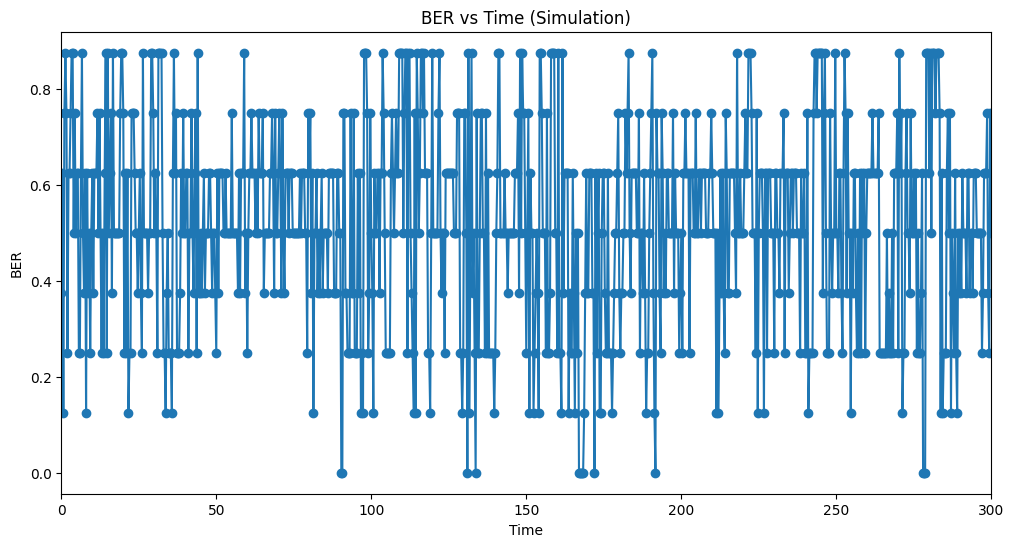

<Figure size 640x480 with 0 Axes>

In [13]:
# Now try BER vs "time" where time is just the index of the received bytes
def run_simulations_varying_probs_time(num_simulations, oversampling_factor, probs):
    bytes = flatten(list(map(manchester_encode, [0x7e] * num_simulations))) #np.random.randint(0, 256)
    oversampled_signal = oversample(bytes, oversampling_factor, probs)
    # between each byte in the oversampled signal, there would be around (1 / (sampling_rate / 2)) seconds 
    sampled_signal = sample_signal(oversampled_signal, oversampling_factor)
    sampled_signal_chunks = [sampled_signal[i:i + 16] for i in range(0, len(sampled_signal), 16)]
    times = np.arange(0, len(sampled_signal_chunks) * (1 / (transmission_rate * oversampling_factor)), 1 / (transmission_rate * oversampling_factor))
    bit_error_rates = []
    for sample in sampled_signal_chunks:
        decoded_byte = manchester_decode(sample)
        error_rate = calculate_error_rate(0x7e, decoded_byte)
        print(f"Original: {0x7e}, Decoded: {decoded_byte}, Error Rate: {error_rate:.2%}")
        bit_error_rates.append(error_rate)
    return times, bit_error_rates

num_simulations = 5000
times, ber = run_simulations_varying_probs_time(num_simulations, oversampling_factor, [0.1, 0.1, 0.8])
# Plot BER vs time
plt.figure(figsize=(12, 6))
plt.plot(times, ber, 'o-')
plt.xlabel("Time")
plt.xlim(0, 300)
plt.ylabel("BER")
plt.title("BER vs Time (Simulation)")
plt.show()
plt.savefig("ber_vs_time_sim.png")

